# Week 4 — simple binary CNN for selected pediatric CVD diagnoses

**Research question.** Can a simple 1-D CNN distinguish ECG records associated with one of the 19 *selected cardiovascular disease* codes in `Data/DiseaseCode.csv` from records without those selected codes? This is **not** normal-vs-abnormal ECG classification or diagnosis of every possible CVD. The negative group may contain other cardiovascular conditions, other diseases, and abnormal ECG statements. Labels come from the `ICD-10 code` field in `Data/AttributesDictionary.csv`, not the header ECG interpretation or `AHA_code`/`CHN_code`. The recorded labels are diagnosis metadata, not an independently adjudicated ground truth.

This notebook uses the original Week 4 `SimpleECGModel` architecture, raw WFDB signals in mV with per-present-lead z-score normalization, the first 10 seconds (or zero-padded shorter records), and validation at the **record** level. The deterministic patient partition follows `NoteBooks/Week6/phase1_training.py` (sorted patient IDs, seed 42, 70/15/15). Test patients are reserved and never loaded into the model. Validation is used for checkpoint selection, so its reported performance is exploratory. No Week 5 or Week 6 experiment is run here.

In [1]:
from pathlib import Path
import os, random, sys, platform, importlib.util
import numpy as np, pandas as pd, wfdb, torch, matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'Data/AttributesDictionary.csv').exists())
DATA = ROOT/'Data'; RECORDS = ROOT/'Child_ECG/Child_ecg'; WEEK4 = ROOT/'NoteBooks/Week4'
SEED=42; FS=500; N_SAMPLES=5000; BATCH_SIZE=32; MAX_EPOCHS=5; LR=1e-3
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
print('Python:',sys.executable,platform.python_version())
print('Torch:',torch.__version__,'compiled CUDA:',torch.version.cuda,'available:',torch.cuda.is_available())
print('WFDB:',wfdb.__version__,'NumPy:',np.__version__,'pandas:',pd.__version__)
print('Project:',ROOT)
assert Path(sys.executable).resolve() == (ROOT/'venv/bin/python').resolve(), 'Select the existing project venv kernel.'
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Training device:',DEVICE)

Python: /home/souhit/Documents/Research/Pediatric_ECG/venv/bin/python 3.13.5
Torch: 2.6.0+cu124 compiled CUDA: 12.4 available: True
WFDB: 4.3.1 NumPy: 2.5.2 pandas: 2.3.3
Project: /home/souhit/Documents/Research/Pediatric_ECG
Training device: cuda


## Metadata and exact target construction

`DiseaseCode.csv` has 19 selected CVD code rows and an “Other diseases” catchall row. Codes with prefixes such as `(FO) Q21.1` are kept intact; removing the qualifier would alter the dataset's categories. A record is positive if **any** semicolon-delimited ICD token matches a selected code exactly. Multiple diagnoses can coexist. Missing or unmatched tokens must not silently be relabeled positive. See the source CSV and the [dataset paper](https://www.nature.com/articles/s41597-025-05225-z) for context. The paper reports 3,516 in the abstract and an early methods passage, but 3,716 in a later methods passage and table. The local metadata resolves the count for this exact code definition at 3,716; it does not resolve why the paper has conflicting figures.

In [2]:
meta=pd.read_csv(DATA/'AttributesDictionary.csv')
disease=pd.read_csv(DATA/'DiseaseCode.csv')
selected_codes=set(disease.loc[disease['Disease Type']!='Other diseases(OD)','ICD-10 Code'].astype(str).str.strip())
assert len(selected_codes)==19

def icd_tokens(value):
    return [x.strip().strip("'\"").strip() for x in str(value).split(';') if x.strip()]

meta['target']=meta['ICD-10 code'].map(lambda s: int(bool(set(icd_tokens(s)) & selected_codes)))
assert meta['Filename'].is_unique and meta['ECG_ID'].is_unique
assert meta['Patient_ID'].notna().all() and meta['ICD-10 code'].notna().all()
assert meta['target'].sum()==3716, 'Local target count differs from the audited metadata; investigate before training.'
assert len(meta)==14190
print('Records:',len(meta),'patients:',meta.Patient_ID.nunique())
print('Selected CVD-positive:',int(meta.target.sum()),'selected CVD-negative:',int((1-meta.target).sum()))
print('Selected codes:', sorted(selected_codes))
print('Lead counts:',meta.Lead.value_counts().sort_index().to_dict())
print('Duration range (s):',meta.Sampling_point.min()/FS,meta.Sampling_point.max()/FS)
print('Negative means no selected code; it does not mean healthy, normal ECG, or CVD-free.')

Records: 14190 patients: 11643
Selected CVD-positive: 3716 selected CVD-negative: 10474
Selected codes: ['(F) I40.0', '(FO) Q21.1', '(OSD) Q21.1', '(V) I40.0', 'I37.0', 'I40.9', 'I42.0', 'I42.2', 'I42.9', 'I51.4', 'M30.3', 'Q21.0', 'Q21.1', 'Q21.2', 'Q21.3', 'Q22.1', 'Q24.8', 'Q25.0', 'Q25.6']
Lead counts: {9: 1856, 12: 12334}
Duration range (s): 5.0 120.0
Negative means no selected code; it does not mean healthy, normal ECG, or CVD-free.


## Patient-level partition

Replicate the historical Week 6 patient allocation to avoid overlap with its frozen test group. The partition uses only patient IDs; labels do not influence the split. We train on training patients and evaluate only validation patients. The third set is held out without ECG reads or outcome calculation.

In [3]:
patients=sorted(meta.Patient_ID.unique().tolist())
random.Random(SEED).shuffle(patients)
n_train=int(0.70*len(patients)); n_val=int(0.15*len(patients))
train_ids=set(patients[:n_train]); val_ids=set(patients[n_train:n_train+n_val]); heldout_ids=set(patients[n_train+n_val:])
assert not (train_ids & val_ids or train_ids & heldout_ids or val_ids & heldout_ids)
train_df=meta.loc[meta.Patient_ID.isin(train_ids)].reset_index(drop=True)
val_df=meta.loc[meta.Patient_ID.isin(val_ids)].reset_index(drop=True)
assert len(train_df)==9943 and len(val_df)==2169
assert train_df.target.sum()==2595 and val_df.target.sum()==583
assert all((RECORDS/(f+'.hea')).is_file() for f in meta.Filename)
print('Patients: train',len(train_ids),'validation',len(val_ids),'held out',len(heldout_ids))
print('Records: train',len(train_df),'validation',len(val_df))
print('Positive records: train',int(train_df.target.sum()),'validation',int(val_df.target.sum()))
print('Training prevalence:',round(train_df.target.mean(),4),'validation prevalence:',round(val_df.target.mean(),4))

Patients: train 8150 validation 1746 held out 1747
Records: train 9943 validation 2169
Positive records: train 2595 validation 583
Training prevalence: 0.261 validation prevalence: 0.2688


## Signal loading and original Week 4 CNN

WFDB lead names are mapped to the standard 12-lead positions. Nine-lead records lack V2/V4/V6; those positions remain zero. Each *observed* lead is standardized using its own first-window mean and standard deviation; missing leads and temporal padding stay zero. This removes absolute amplitude information, which is a scientific limitation. The model architecture is imported unchanged from `NoteBooks/Week4/pytorch_starter.py`; its original dataset/labeling code is not used.

In [4]:
LEADS=['I','II','III','AVR','AVL','AVF','V1','V2','V3','V4','V5','V6']
LEAD_INDEX={lead:i for i,lead in enumerate(LEADS)}
class CVDRecordDataset(Dataset):
    def __init__(self, frame):
        self.frame=frame[['Filename','target']].reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self, i):
        row=self.frame.iloc[i]
        signal, fields=wfdb.rdsamp(str(RECORDS/row.Filename), sampto=min(N_SAMPLES, int(meta_by_filename[row.Filename])))
        assert fields['fs']==FS
        assert np.isfinite(signal).all(), f'Nonfinite signal: {row.Filename}'
        output=np.zeros((12,N_SAMPLES),dtype=np.float32)
        for j, lead in enumerate(fields['sig_name']):
            key=lead.upper()
            assert key in LEAD_INDEX, f'Unexpected lead {lead}: {row.Filename}'
            x=signal[:,j].astype(np.float32)
            std=x.std()
            output[LEAD_INDEX[key],:len(x)]=(x-x.mean())/std if std>1e-8 else 0
        return torch.from_numpy(output), int(row.target)

meta_by_filename=dict(zip(meta.Filename,meta.Sampling_point))
model_spec=importlib.util.spec_from_file_location('week4_original',WEEK4/'pytorch_starter.py')
week4_original=importlib.util.module_from_spec(model_spec); model_spec.loader.exec_module(week4_original)
model=week4_original.SimpleECGModel(num_classes=2).to(DEVICE)
# Materialize LazyLinear before optimizer construction.
with torch.no_grad(): model(torch.zeros(1,12,N_SAMPLES,device=DEVICE))
print(model)
print('Trainable parameters:',sum(p.numel() for p in model.parameters()))
train_loader=DataLoader(CVDRecordDataset(train_df),batch_size=BATCH_SIZE,shuffle=True,num_workers=2)
val_loader=DataLoader(CVDRecordDataset(val_df),batch_size=BATCH_SIZE,shuffle=False,num_workers=2)

SimpleECGModel(
  (conv1): Conv1d(12, 16, kernel_size=(5,), stride=(1,), padding=(2,))
  (relu): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=40000, out_features=2, bias=True)
)
Trainable parameters: 80978


## Training and validation

Five epochs, Adam (learning rate 0.001), unweighted cross entropy, fixed 0.5 decision threshold. Choose the checkpoint with lowest validation loss; report its validation metrics. Class imbalance is left unweighted to observe the simple Week 4 model's behavior. Loss is averaged by record. Validation metrics are record-level and can give extra weight to patients with repeat ECGs.

In [5]:
criterion=torch.nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=LR)

def run_epoch(loader, training=False):
    model.train(training)
    total_loss=0.; ys=[]; probs=[]
    for x,y in loader:
        x=x.to(DEVICE); y=y.to(DEVICE)
        with torch.set_grad_enabled(training):
            logits=model(x); loss=criterion(logits,y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
        total_loss+=loss.item()*len(y)
        ys.extend(y.cpu().numpy().tolist())
        probs.extend(torch.softmax(logits,dim=1)[:,1].detach().cpu().numpy().tolist())
    return total_loss/len(loader.dataset), np.asarray(ys), np.asarray(probs)

def evaluate(y,p):
    pred=(p>=0.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(accuracy=accuracy_score(y,pred),balanced_accuracy=balanced_accuracy_score(y,pred),
                precision=precision_score(y,pred,zero_division=0),recall=recall_score(y,pred,zero_division=0),
                specificity=tn/(tn+fp),f1=f1_score(y,pred,zero_division=0),
                roc_auc=roc_auc_score(y,p),average_precision=average_precision_score(y,p),
                tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))

history=[]; best_loss=float('inf'); best_epoch=None
checkpoint=WEEK4/'Week4_CVD_Binary_CNN_best.pth'
for epoch in range(1,MAX_EPOCHS+1):
    train_loss, train_y, train_p=run_epoch(train_loader,True)
    val_loss,val_y,val_p=run_epoch(val_loader,False)
    train_metrics=evaluate(train_y,train_p); val_metrics=evaluate(val_y,val_p)
    history.append({'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss,
                    'train_accuracy':train_metrics['accuracy'],'train_balanced_accuracy':train_metrics['balanced_accuracy'],
                    'val_accuracy':val_metrics['accuracy'],'val_balanced_accuracy':val_metrics['balanced_accuracy'],
                    'val_recall':val_metrics['recall'],'val_roc_auc':val_metrics['roc_auc']})
    if val_loss<best_loss:
        best_loss=val_loss; best_epoch=epoch
        torch.save({'model_state_dict':model.state_dict(),'epoch':epoch,'validation_loss':val_loss,
                    'target':'Any exact match to the 19 selected codes in Data/DiseaseCode.csv',
                    'seed':SEED,'input_samples':N_SAMPLES,'lead_order':LEADS},checkpoint)
    print(f'Epoch {epoch}: train loss {train_loss:.4f}, val loss {val_loss:.4f}, '
          f'val accuracy {val_metrics["accuracy"]:.4f}, balanced accuracy {val_metrics["balanced_accuracy"]:.4f}, '
          f'val recall {val_metrics["recall"]:.4f}, AUROC {val_metrics["roc_auc"]:.4f}',flush=True)

history_df=pd.DataFrame(history)
display(history_df.round(4))
print('Best epoch by validation loss:',best_epoch,'checkpoint:',checkpoint)

Epoch 1: train loss 0.6805, val loss 0.5526, val accuracy 0.7446, balanced accuracy 0.6079, val recall 0.3122, AUROC 0.6763


Epoch 2: train loss 0.4694, val loss 0.6257, val accuracy 0.7404, balanced accuracy 0.5546, val recall 0.1527, AUROC 0.6663


Epoch 3: train loss 0.4000, val loss 0.6723, val accuracy 0.6851, balanced accuracy 0.5954, val recall 0.4014, AUROC 0.6261


Epoch 4: train loss 0.3399, val loss 0.7669, val accuracy 0.7229, balanced accuracy 0.5713, val recall 0.2436, AUROC 0.6212


Epoch 5: train loss 0.2732, val loss 0.8261, val accuracy 0.6888, balanced accuracy 0.5849, val recall 0.3602, AUROC 0.6271


,epoch,train_loss,val_loss,train_accuracy,train_balanced_accuracy,val_accuracy,val_balanced_accuracy,val_recall,val_roc_auc
0,1,0.6805,0.5526,0.7084,0.5470,0.7446,0.6079,0.3122,0.6763
1,2,0.4694,0.6257,0.7951,0.6691,0.7404,0.5546,0.1527,0.6663
2,3,0.4000,0.6723,0.8284,0.7275,0.6851,0.5954,0.4014,0.6261
3,4,0.3399,0.7669,0.8541,0.7774,0.7229,0.5713,0.2436,0.6212
4,5,0.2732,0.8261,0.8861,0.8287,0.6888,0.5849,0.3602,0.6271


Best epoch by validation loss: 1 checkpoint: /home/souhit/Documents/Research/Pediatric_ECG/NoteBooks/Week4/Week4_CVD_Binary_CNN_best.pth


## Selected checkpoint: validation metrics and confusion matrix

These are exploratory validation results at threshold 0.5. The test set remains frozen. Majority-class accuracy and positive prevalence provide useful context.

Selected epoch: 1 validation loss: 0.5526
accuracy                0.7446
balanced_accuracy       0.6079
precision               0.5433
recall                  0.3122
specificity             0.9035
f1                      0.3965
roc_auc                 0.6763
average_precision       0.4574
tn                   1433.0000
fp                    153.0000
fn                    401.0000
tp                    182.0000
Always-negative validation accuracy: 0.7312
Validation positive prevalence / random-ranking AP: 0.2688


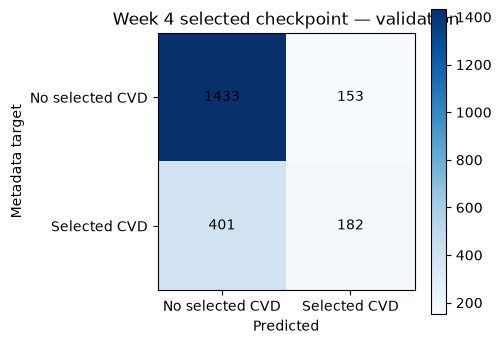

In [6]:
saved=torch.load(checkpoint,map_location=DEVICE,weights_only=False)
model.load_state_dict(saved['model_state_dict'])
selected_loss,val_y,val_p=run_epoch(val_loader,False)
results=evaluate(val_y,val_p)
print('Selected epoch:',saved['epoch'],'validation loss:',round(selected_loss,4))
print(pd.Series(results).round(4).to_string())
print('Always-negative validation accuracy:',round(1-val_y.mean(),4))
print('Validation positive prevalence / random-ranking AP:',round(val_y.mean(),4))
cm=confusion_matrix(val_y,(val_p>=0.5).astype(int),labels=[0,1])
fig,ax=plt.subplots(figsize=(5,4))
img=ax.imshow(cm,cmap='Blues')
for (i,j),n in np.ndenumerate(cm): ax.text(j,i,str(n),ha='center',va='center')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['No selected CVD','Selected CVD'],
       yticklabels=['No selected CVD','Selected CVD'],xlabel='Predicted',ylabel='Metadata target',
       title='Week 4 selected checkpoint — validation')
fig.colorbar(img,ax=ax); plt.tight_layout(); plt.show()

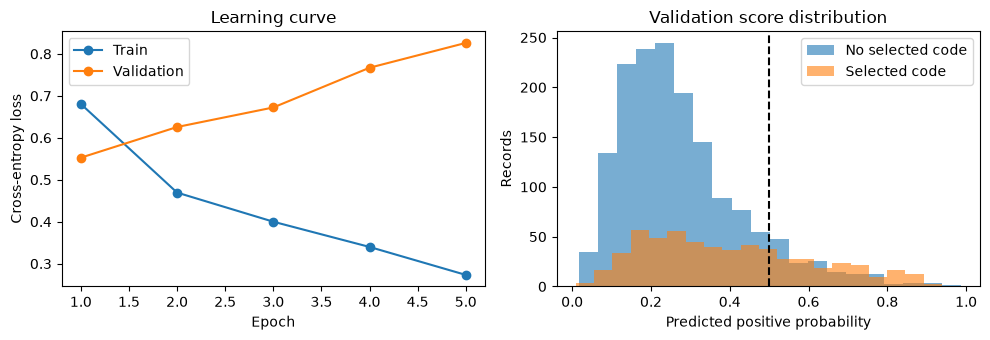

In [7]:
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].plot(history_df.epoch,history_df.train_loss,marker='o',label='Train')
ax[0].plot(history_df.epoch,history_df.val_loss,marker='o',label='Validation')
ax[0].set(xlabel='Epoch',ylabel='Cross-entropy loss',title='Learning curve'); ax[0].legend()
ax[1].hist(val_p[val_y==0],bins=20,alpha=.6,label='No selected code')
ax[1].hist(val_p[val_y==1],bins=20,alpha=.6,label='Selected code')
ax[1].axvline(.5,color='black',linestyle='--'); ax[1].set(xlabel='Predicted positive probability',ylabel='Records',title='Validation score distribution'); ax[1].legend()
plt.tight_layout(); plt.show()

## Reflection and limitations

**Observed:** The lowest validation loss occurred at epoch 1 (0.5526). From epochs 1 to 5, training loss fell from 0.6805 to 0.2732 while validation loss rose to 0.8261. This pattern is consistent with overfitting, although this single run cannot identify its cause.

At the selected checkpoint and fixed 0.5 threshold, validation accuracy was 0.7446, only modestly above the always-negative accuracy of 0.7312. The model found 182 of 583 positive records (recall 0.3122) and missed 401; specificity was 0.9035, precision 0.5433, and F1 0.3965. AUROC was 0.6763 and average precision 0.4574 versus positive prevalence 0.2688. Thus the model ranks records better than chance but misses most selected-code positives at the specified threshold. These are observations on the validation records, not clinical performance estimates.

**Limitations:** Only the first 10 seconds are used, so later events are unseen; shorter records are padded. Per-lead z-scoring discards absolute voltage, and missing leads are represented as zeros. Nine-lead and 12-lead records may differ systematically. Some patients contribute multiple validation records. Selected-code absence is not evidence of cardiovascular health. The hospitalized cohort cannot establish performance in community screening. Labels are not independently adjudicated here; no external validation is available. Validation was used to choose the checkpoint, so these metrics are exploratory. The frozen test set remains unevaluated. No clinical utility can be inferred from this notebook.